<a href="https://colab.research.google.com/github/jaskiratbudhmaan-ship-it/LocalRepo/blob/main/Machine_Learning_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Decision Tree

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
dataset = pd.read_csv("Social_Network_Ads.csv")
dataset.head(3)

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0


In [ ]:
dataset.isnull().sum()

,0
Age,0
EstimatedSalary,0
Purchased,0


In [ ]:
x = dataset.iloc[:,:-1]
y = dataset["Purchased"]

In [ ]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
sc.fit(x)

StandardScaler()

In [ ]:
x = pd.DataFrame(sc.transform(x),columns=x.columns)

In [ ]:
x

,Age,EstimatedSalary
0,-1.781797,-1.490046
1,-0.253587,-1.460681
2,-1.113206,-0.785290
3,-1.017692,-0.374182
4,-1.781797,0.183751
...,...,...
395,0.797057,-0.844019
396,1.274623,-1.372587
397,1.179110,-1.460681
398,-0.158074,-1.078938


In [ ]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [ ]:
from sklearn.tree import DecisionTreeClassifier
dt = DecisionTreeClassifier()
dt.fit(x_train,y_train)


DecisionTreeClassifier()

In [ ]:
dt.score(x_test,y_test)*100

83.75

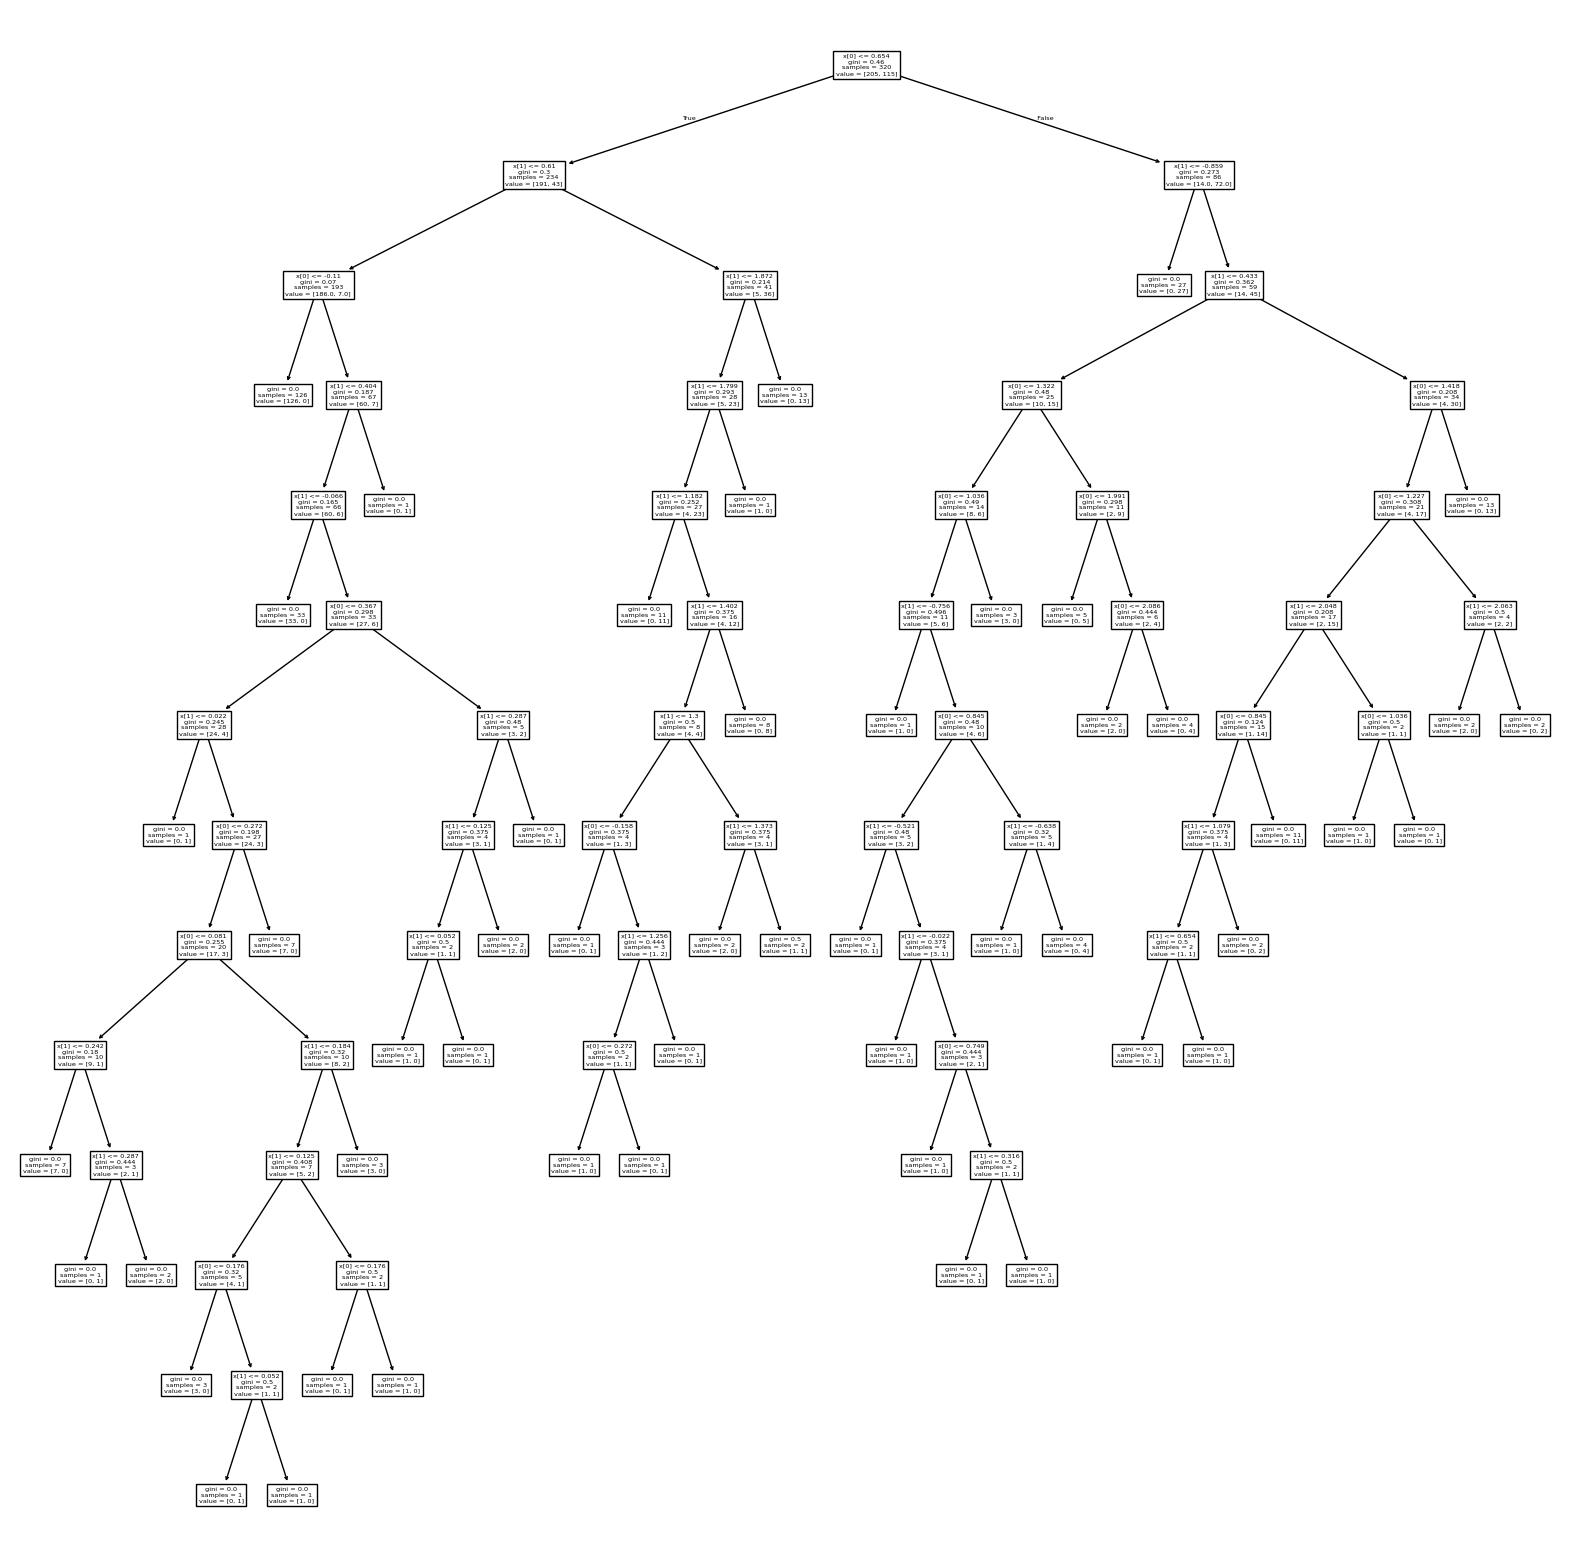

In [ ]:
from sklearn.tree import plot_tree
plt.figure(figsize=(20,20))
plot_tree(dt)
plt.show()


In [ ]:
plt.savefig("decisiontree.jpg")

<Figure size 640x480 with 0 Axes>

In [ ]:
dt1 = DecisionTreeClassifier(criterion="entropy")
dt1.fit(x_train,y_train)

DecisionTreeClassifier(criterion='entropy')

In [ ]:
dt1.score(x_test,y_test)*100

83.75

In [ ]:
dataset

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0
3,27,57000,0
4,19,76000,0
...,...,...,...
395,46,41000,1
396,51,23000,1
397,50,20000,1
398,36,33000,0


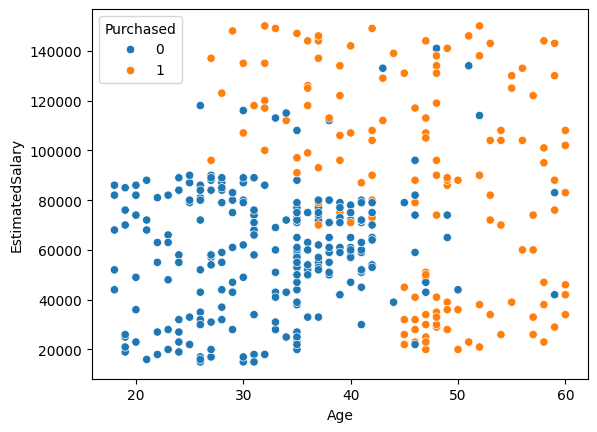

In [ ]:
sns.scatterplot(data=dataset,x="Age",y="EstimatedSalary",hue="Purchased")
plt.show()

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


<Axes: >

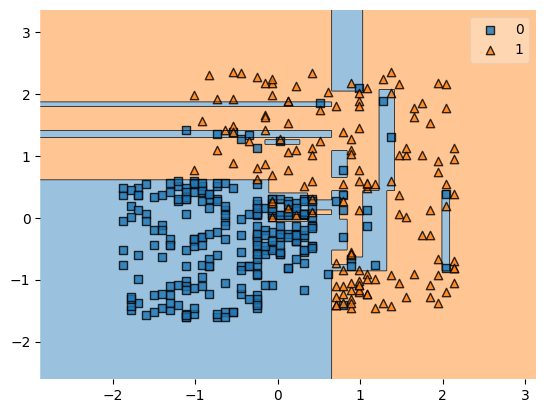

In [ ]:
from mlxtend.plotting import plot_decision_regions
plot_decision_regions(x.to_numpy(),y.to_numpy(),clf=dt)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


<Axes: >

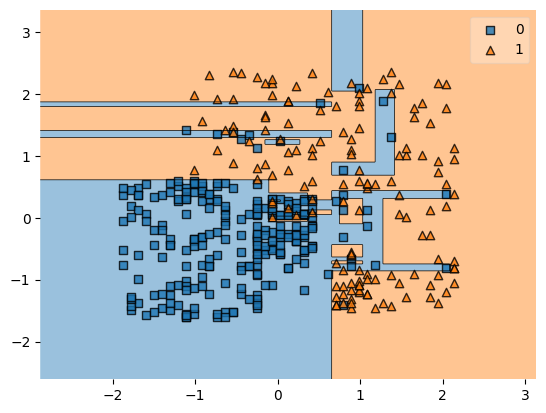

In [ ]:
plot_decision_regions(x.to_numpy(),y.to_numpy(),clf=dt1)

# Pre and Post Pruning

Check for overfitting

In [ ]:
dt.score(x_test,y_test)*100

83.75

In [ ]:
dt.score(x_train,y_train)*100

99.6875

There is a huge difference between the accuracy of model when tested on training data and testing data . The accuracy is highest with training data which indicates that our model is overfitted.

To avoid overfitting we will use pruning

Pre-Pruning

In [ ]:
dt = DecisionTreeClassifier(max_depth=5)
dt.fit(x_train,y_train)

DecisionTreeClassifier(max_depth=5)

In [ ]:
dt.score(x_test,y_test)*100

90.0

In [ ]:
dt.score(x_train,y_train)*100


93.4375

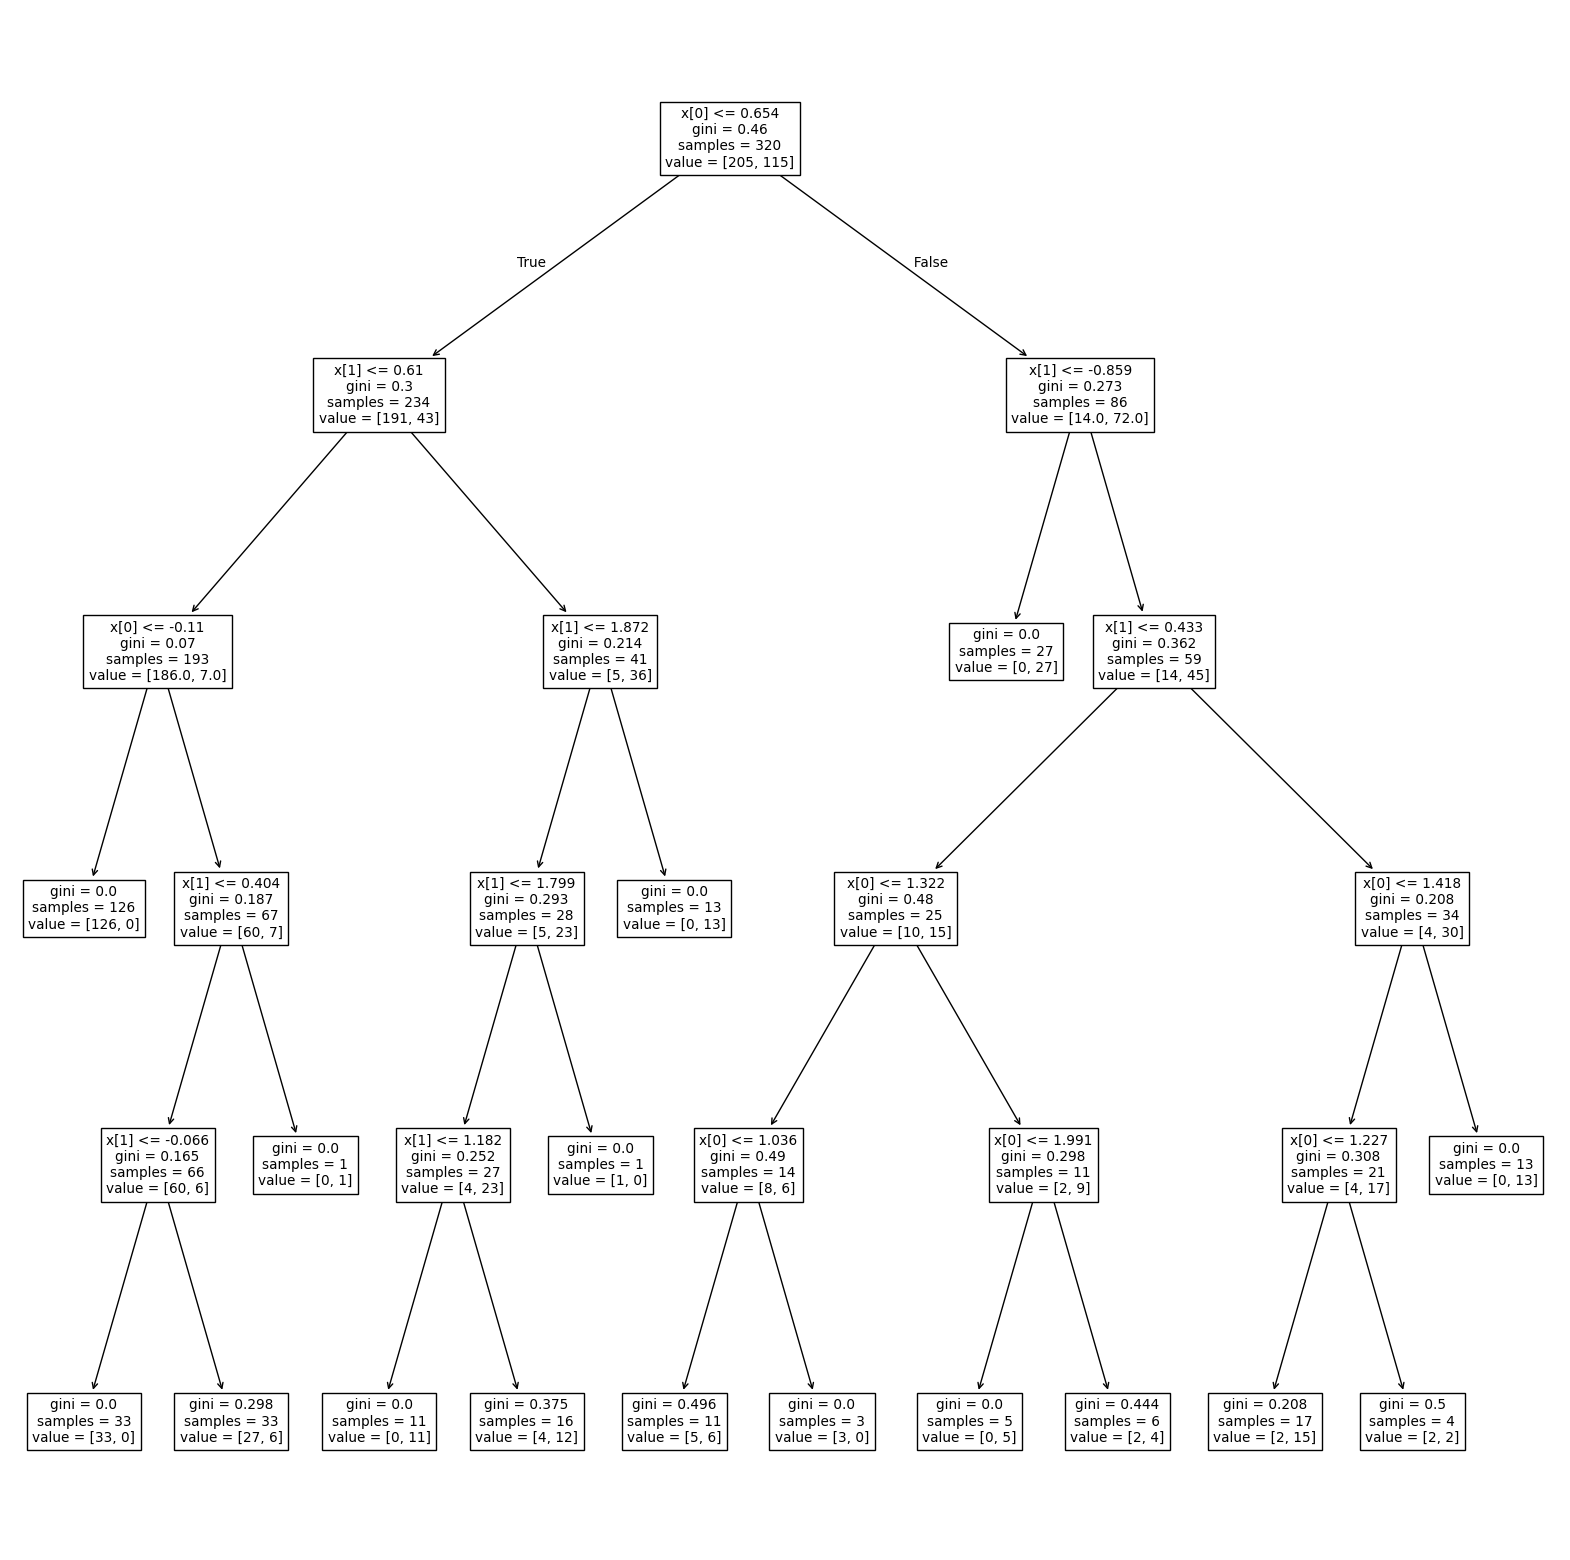

In [ ]:
from sklearn.tree import plot_tree
plt.figure(figsize=(20,20))
plot_tree(dt)
plt.show()


We can clearly see now that the difference between the new accuracies is less.

Post-Pruning

When we need to get the least dfference of error between training and testing data we require post pruning where we use loop nd check model's score with different max_depths.

In [ ]:
for i in range(1,20):
  dt2 = DecisionTreeClassifier(max_depth=i)
  dt2.fit(x_train,y_train)
  print(i,dt2.score(x_test,y_test)*100,dt2.score(x_train,y_train)*100)

1 90.0 82.1875
2 91.25 91.875
3 91.25 91.875
4 91.25 93.125
5 90.0 93.4375
6 86.25 95.0
7 85.0 96.875
8 85.0 97.5
9 85.0 98.125
10 85.0 98.4375
11 83.75 99.0625
12 83.75 99.375
13 83.75 99.6875
14 83.75 99.6875
15 83.75 99.6875
16 83.75 99.6875
17 83.75 99.6875
18 83.75 99.6875
19 83.75 99.6875


# Decision Tree Regression

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [ ]:
dataset = pd.read_csv("Salary_Data.csv")
dataset.head(3)

,YearsExperience,Age,Salary
0,1.1,21.0,39343
1,1.3,21.5,46205
2,1.5,21.7,37731


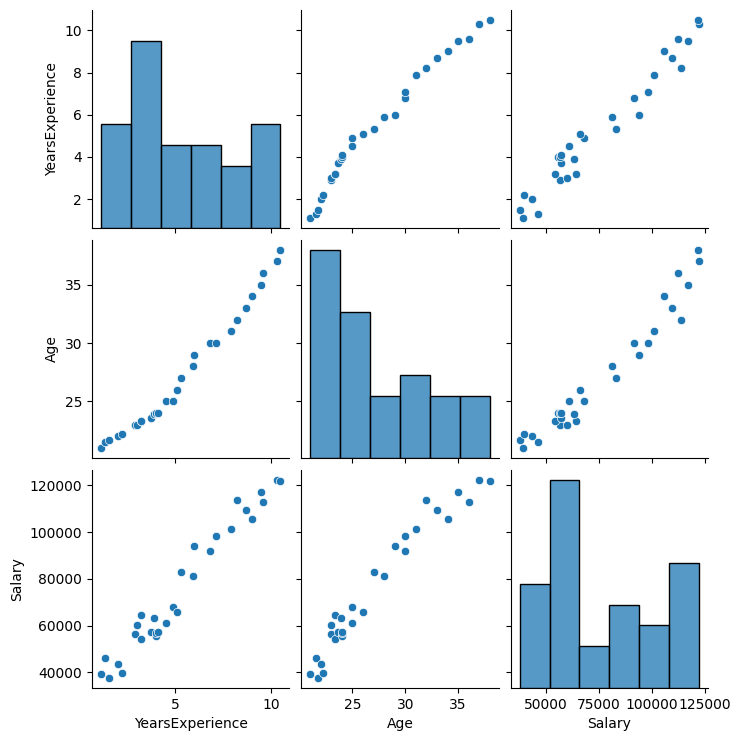

In [ ]:
sns.pairplot(data=dataset)
plt.show()

In [ ]:
x = dataset.iloc[:,:-1]
y = dataset["Salary"]

In [ ]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [ ]:
from sklearn.tree import DecisionTreeRegressor,plot_tree
dt = DecisionTreeRegressor()
dt.fit(x_train,y_train)

DecisionTreeRegressor()

In [ ]:
dt.score(x_test,y_test)*100

80.21759743735161

In [ ]:
dt.score(x_train,y_train)*100

99.99631319936537

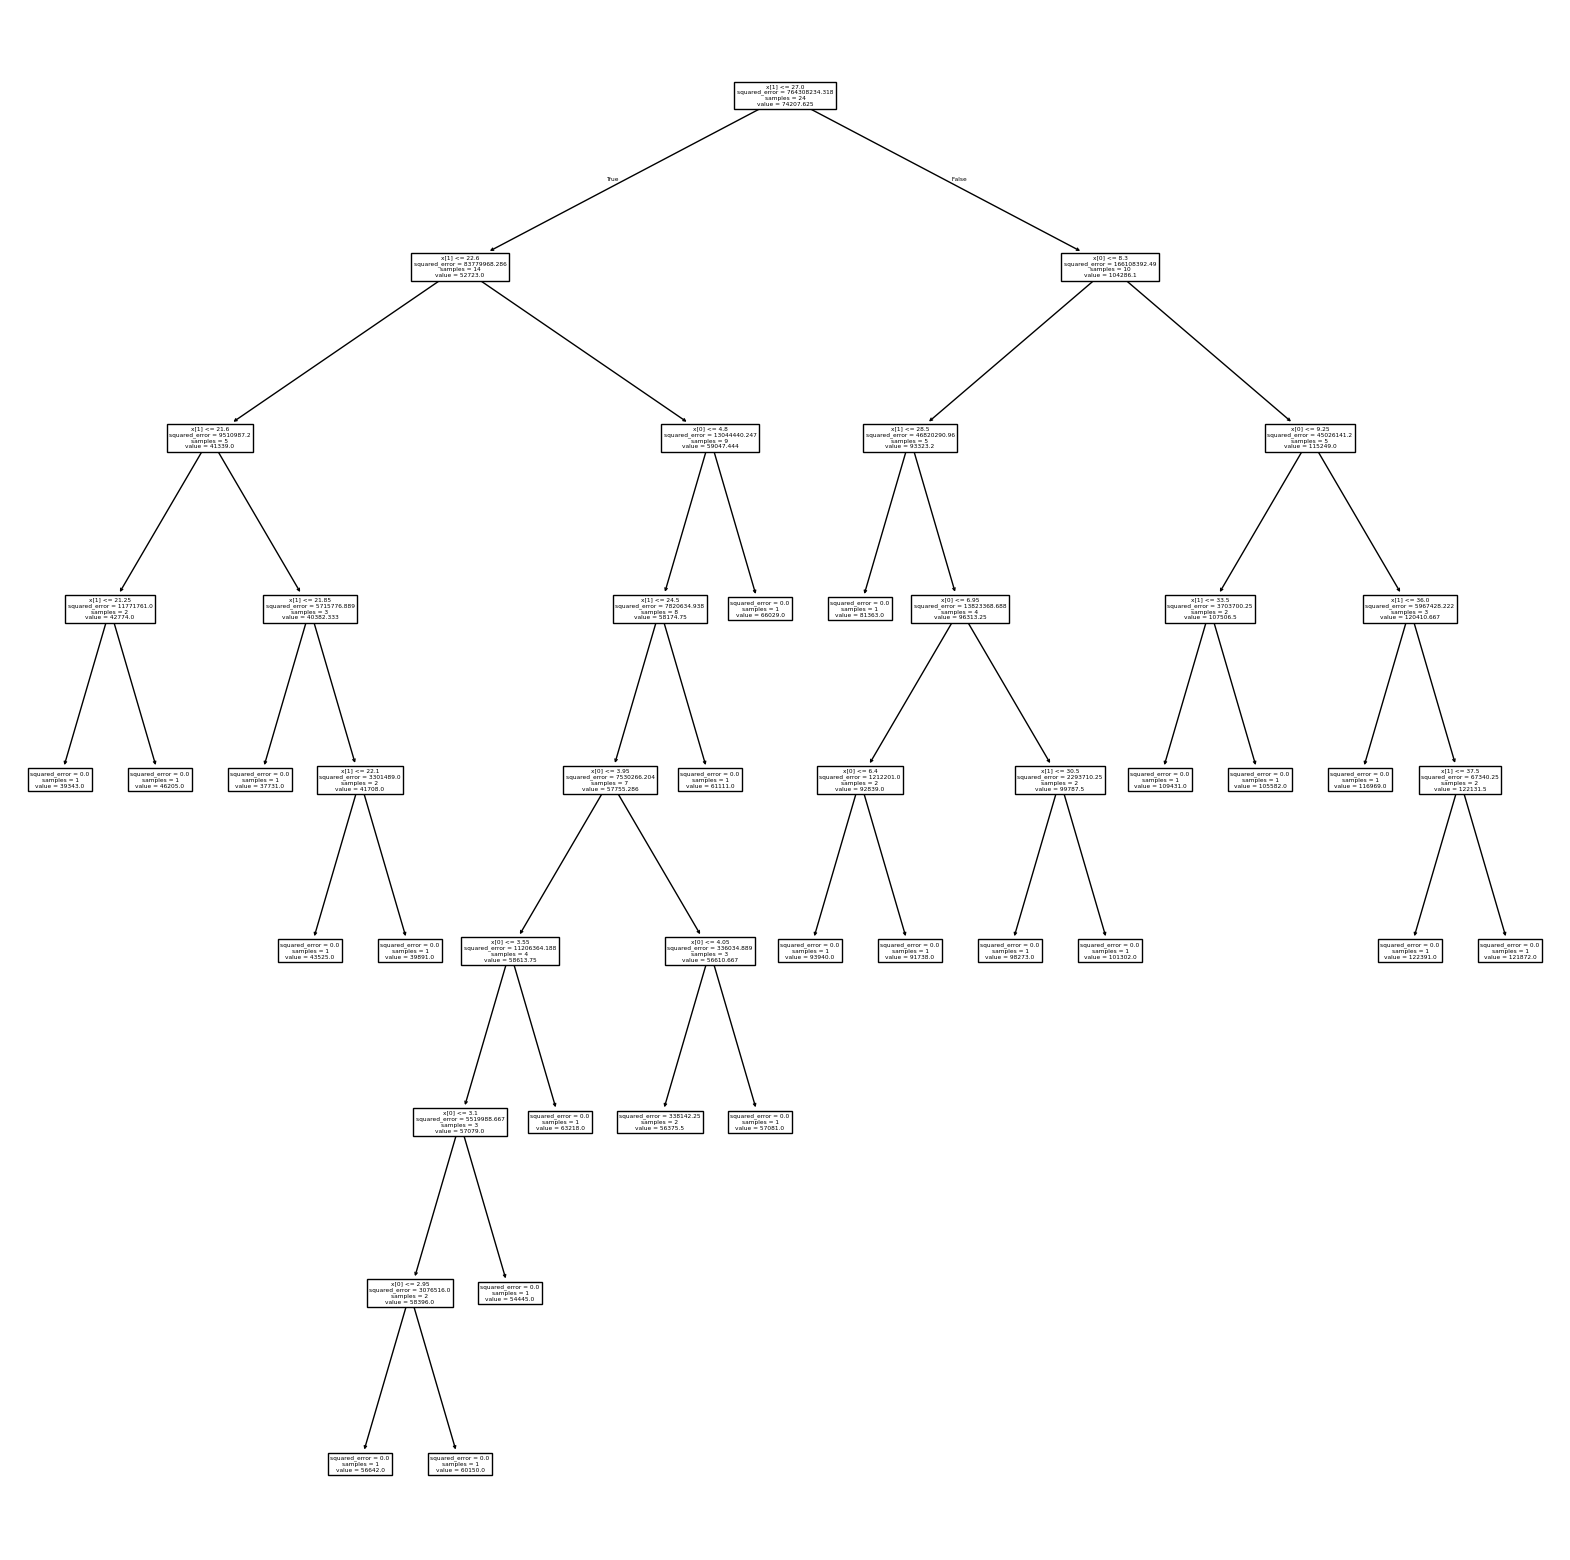

In [ ]:
plt.figure(figsize=(20,20))
plot_tree(dt)
plt.show()

# K-NN (K-Nearest Neighbours)

In [ ]:
dataset = pd.read_csv("Social_Network_Ads.csv")
dataset.head(3)

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0


In [ ]:
dataset.isnull().sum()

,0
Age,0
EstimatedSalary,0
Purchased,0


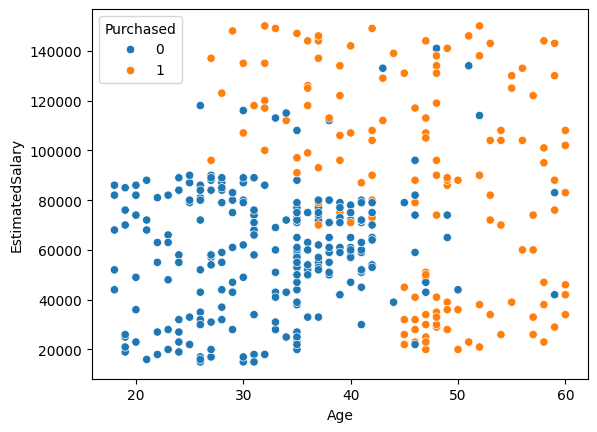

In [ ]:
sns.scatterplot(x="Age",y="EstimatedSalary",hue="Purchased",data=dataset)
plt.show()

In [ ]:
x = dataset.iloc[:,:-1]
y = dataset["Purchased"]

In [ ]:
from sklearn.preprocessing import StandardScaler
sc = StandardScaler()
sc.fit(x)

StandardScaler()

In [ ]:
x = pd.DataFrame(sc.transform(x),columns=x.columns)

In [ ]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [ ]:
from sklearn.neighbors import KNeighborsClassifier
knn = KNeighborsClassifier(n_neighbors=5,p=2) # n_neighbors --> value of k , p = 2 means use eucledian's distance
knn.fit(x_train,y_train)


KNeighborsClassifier()

In [ ]:
knn.score(x_test,y_test)*100

92.5

In [ ]:
knn.score(x_train,y_train)*100

90.9375

To decide the best value of k we can also use loop

In [ ]:
for i in range(1,30):
   knn1 = KNeighborsClassifier(n_neighbors=i)
   knn1.fit(x_train,y_train)
   print(i,knn1.score(x_test,y_test),knn1.score(x_train,y_train))

1 0.85 0.996875
2 0.8625 0.9125
3 0.925 0.925
4 0.925 0.915625
5 0.925 0.909375
6 0.9 0.909375
7 0.9375 0.91875
8 0.925 0.90625
9 0.9375 0.9125
10 0.925 0.90625
11 0.925 0.909375
12 0.925 0.9125
13 0.925 0.915625
14 0.925 0.90625
15 0.925 0.90625
16 0.925 0.9
17 0.925 0.903125
18 0.925 0.9
19 0.925 0.909375
20 0.9375 0.9
21 0.925 0.903125
22 0.9375 0.9
23 0.9375 0.903125
24 0.9375 0.89375
25 0.9375 0.9
26 0.9375 0.89375
27 0.925 0.89375
28 0.9375 0.8875
29 0.9375 0.8875


In [ ]:
x

,Age,EstimatedSalary
0,-1.781797,-1.490046
1,-0.253587,-1.460681
2,-1.113206,-0.785290
3,-1.017692,-0.374182
4,-1.781797,0.183751
...,...,...
395,0.797057,-0.844019
396,1.274623,-1.372587
397,1.179110,-1.460681
398,-0.158074,-1.078938


In [ ]:
knn.predict([[-0.253587,-1.460681]])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


array([0])

Graph

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but KNeighborsClassifier was fitted with feature names
  warnings.warn(


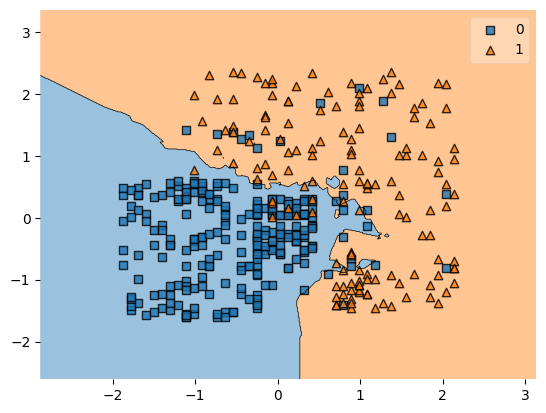

In [ ]:
from mlxtend.plotting import plot_decision_regions
plot_decision_regions(x.to_numpy(),y.to_numpy(),clf=knn)
plt.show()